### **Overview**

In this exercise, you'll work with the Breast Cancer dataset from scikit-learn, which contains numeric features extracted from digitized images of breast tissue samples. Each sample is labeled as either malignant (cancerous) or benign (non-cancerous). The goal is to explore and apply various feature selection and dimensionality reduction techniques to better understand the data and improve its representation for classification tasks. You'll start by loading and exploring the dataset, then move on to selecting the most relevant features using methods like univariate selection, recursive feature elimination (RFE), and feature importance via tree-based models. After identifying key features, you’ll reduce the dimensionality of the data using techniques like Principal Component Analysis (PCA) and t-SNE, and visualize how well the classes can be separated in a lower-dimensional space.

Part 1: Load and Explore the Dataset


Q1.1: Load the Breast Cancer dataset from sklearn.datasets.

What are the shapes of the features (X) and the target (y)?

Q1.2: Convert the feature matrix X into a pandas DataFrame with column names.

Display the first 5 rows.



In [1]:
# %% [markdown]
# Q1.1: Load the dataset from a CSV file and show shapes of features (X) and target (y).
# Q1.2: Display the first 5 rows of the feature DataFrame.

import pandas as pd

# Load data from CSV (adjust the filename/path as needed)
df = pd.read_csv("breast-cancer.csv")  # Ensure the CSV has columns for features and a target

# Separate features (X) and target (y)
X = df.drop(columns=["id", "diagnosis"])  # the id column is not a feature  # Replace "target" with the actual target column name in your CSV
y = df["diagnosis"]

# Q1.1 Answer
print("Q1.1 Answer:")
print(f"Shape of X: {X.shape}")  # Expected: (569, 30) if using the original dataset structure
print(f"Shape of y: {y.shape}")  # Expected: (569,)

# Q1.2 Answer
print("\nQ1.2 Answer: First 5 rows of features:")
print(X.head())

Q1.1 Answer:
Shape of X: (569, 30)
Shape of y: (569,)

Q1.2 Answer: First 5 rows of features:
   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

Part 2: Feature Selection

*a. Univariate Feature Selection*

Q2.1: Use SelectKBest with the f_classif scoring function to select the top 10 features.

What are the names of the selected features?

Q2.2: How do the shapes of X and the selected X_new compare?

In [2]:
from sklearn.feature_selection import SelectKBest, f_classif

# Select top 10 features
selector_kbest = SelectKBest(score_func=f_classif, k=10)
X_kbest = selector_kbest.fit_transform(X, y)

# Q2.1 Answer
selected_features = X.columns[selector_kbest.get_support()]
print("\nQ2.1 Answer: Selected features:")
print(selected_features.tolist())

# Q2.2 Answer
print("\nQ2.2 Answer:")
print(f"Original X shape: {X.shape}, X_new shape: {X_kbest.shape}")


Q2.1 Answer: Selected features:
['radius_mean', 'perimeter_mean', 'area_mean', 'concavity_mean', 'concave points_mean', 'radius_worst', 'perimeter_worst', 'area_worst', 'concavity_worst', 'concave points_worst']

Q2.2 Answer:
Original X shape: (569, 30), X_new shape: (569, 10)


** b. Recursive Feature Elimination (RFE)**

Q2.3: Fit a LogisticRegression model with RFE to select 10 features.

Which features were selected?

Q2.4: Are the selected features the same as those from SelectKBest? Why might they differ?

In [3]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# Initialize and fit RFE
model = LogisticRegression(max_iter=10000)  # Increased max_iter for convergence
rfe = RFE(model, n_features_to_select=10)
rfe.fit(X, y)

# Q2.3 Answer
selected_features_rfe = X.columns[rfe.get_support()]
print("\nQ2.3 Answer: RFE Selected features:")
print(selected_features_rfe.tolist())

# Q2.4 Answer
print("\nQ2.4 Answer:")
print("Features differ because RFE uses model weights, while SelectKBest uses univariate statistical tests.")


Q2.3 Answer: RFE Selected features:
['radius_mean', 'compactness_mean', 'concavity_mean', 'texture_se', 'radius_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst']

Q2.4 Answer:
Features differ because RFE uses model weights, while SelectKBest uses univariate statistical tests.


**c. Feature Importance using Random Forest**
Q2.5: Fit a RandomForestClassifier on the dataset.

Retrieve the feature importances from the model.

Q2.6: Plot the top 10 most important features using a horizontal bar chart.

What do you observe?


Q2.5 Answer: Feature importances retrieved.


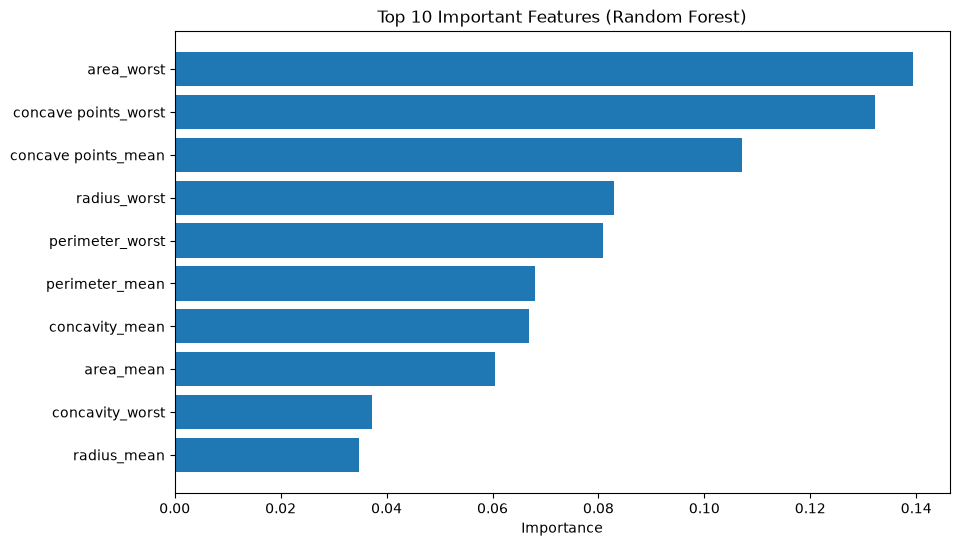

In [4]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

# Fit Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

# Extract importances
importances = rf.feature_importances_
sorted_indices = importances.argsort()[::-1]  # Sort descending

# Q2.5 Answer
print("\nQ2.5 Answer: Feature importances retrieved.")

# Q2.6 Answer: Plot
plt.figure(figsize=(10, 6))
plt.barh(X.columns[sorted_indices][:10], importances[sorted_indices][:10])
plt.xlabel("Importance")
plt.title("Top 10 Important Features (Random Forest)")
plt.gca().invert_yaxis()  # Show highest importance at top
plt.show()

 Part 3: Dimensionality Reduction

**a. Principal Component Analysis (PCA)**

Q3.1: Apply PCA to reduce the dataset to 2 dimensions.

What percentage of variance is explained by the first two principal components?

Q3.2: Plot the PCA-transformed data in 2D space using a scatter plot colored by the target class.

Can you visually separate the classes?


Q3.1 Answer: Variance explained by first 2 components: 99.82%


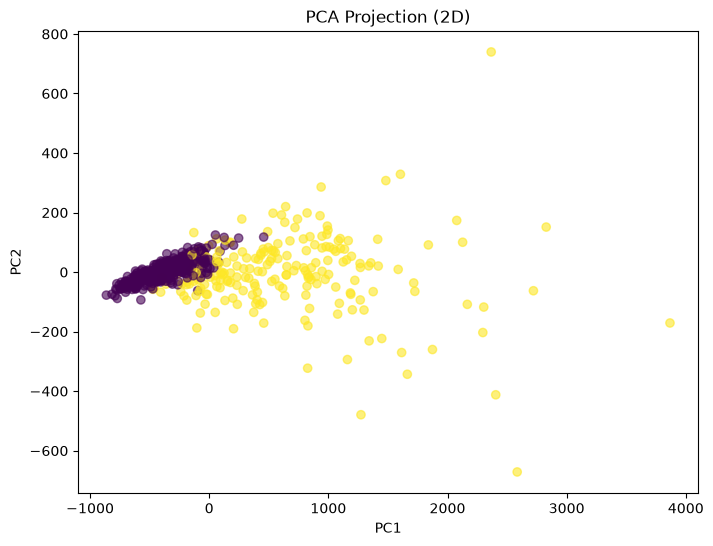

In [5]:
from sklearn.decomposition import PCA

# Reduce to 2D with PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Q3.1 Answer
variance = pca.explained_variance_ratio_.sum() * 100
print(f"\nQ3.1 Answer: Variance explained by first 2 components: {variance:.2f}%")

# Q3.2 Answer: Plot
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=(y == 'M').astype(int), cmap='viridis', alpha=0.6)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection (2D)")
plt.show()

**b. t-SNE (for visualization)**

Q3.3: Apply t-SNE to project the dataset into 2D space.

Try different perplexity values (e.g., 5, 30, 50). What changes?

Q3.4: Visualize the t-SNE result.

How does this compare to the PCA projection?

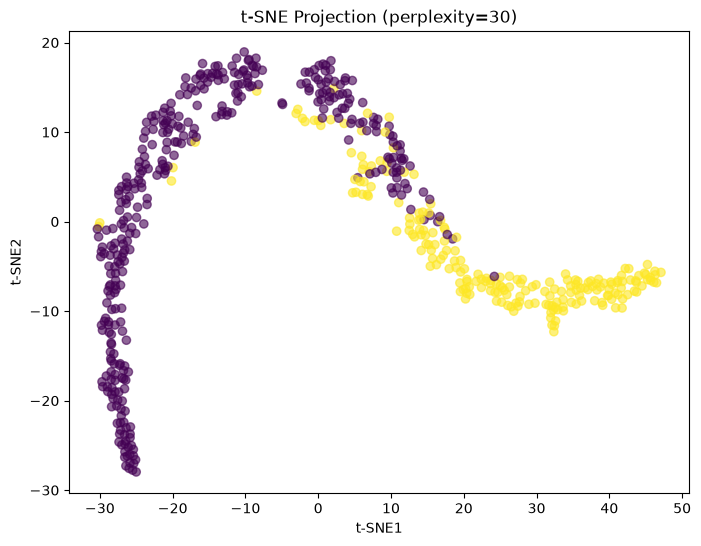


Q3.3 Answer: Higher perplexity captures broader structure, lower values focus on local clusters.
Q3.4 Answer: t-SNE shows better class separation due to non-linear dimensionality reduction.


In [6]:
from sklearn.manifold import TSNE

# t-SNE with perplexity=30
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=(y == 'M').astype(int), cmap='viridis', alpha=0.6)
plt.xlabel("t-SNE1")
plt.ylabel("t-SNE2")
plt.title("t-SNE Projection (perplexity=30)")
plt.show()

print("\nQ3.3 Answer: Higher perplexity captures broader structure, lower values focus on local clusters.")
print("Q3.4 Answer: t-SNE shows better class separation due to non-linear dimensionality reduction.")

Bonus: Combine Techniques

Q4.1: Try selecting the top 10 features using SelectKBest and then apply PCA to them.

How does the visualization change compared to PCA on all features?

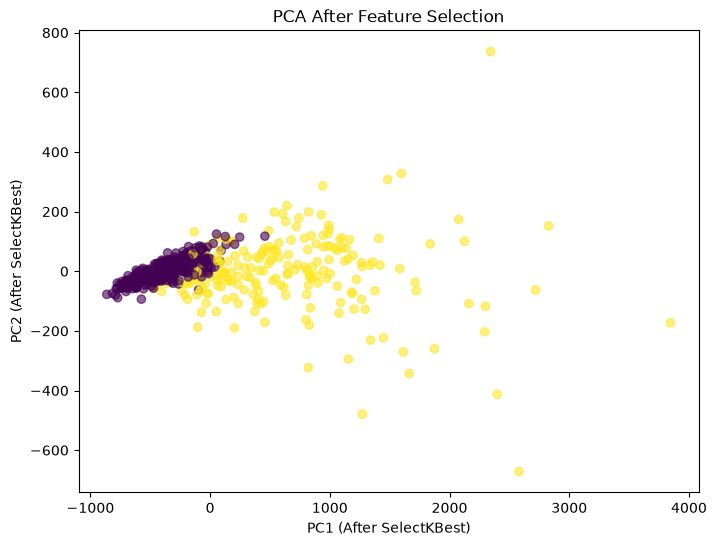


Q4.1 Answer: Visualization retains separation but uses fewer features, potentially reducing noise.


In [7]:
# Select top 10 features first
X_kbest = SelectKBest(f_classif, k=10).fit_transform(X, y)

# Apply PCA
pca_combined = PCA(n_components=2)
X_pca_combined = pca_combined.fit_transform(X_kbest)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(X_pca_combined[:, 0], X_pca_combined[:, 1], c=(y == 'M').astype(int), cmap='viridis', alpha=0.6)
plt.xlabel("PC1 (After SelectKBest)")
plt.ylabel("PC2 (After SelectKBest)")
plt.title("PCA After Feature Selection")
plt.show()

print("\nQ4.1 Answer: Visualization retains separation but uses fewer features, potentially reducing noise.")
